                                                text language
0   Nature, in the broadest sense, is the natural...  English
1  "Nature" can refer to the phenomena of the phy...  English
2  The study of nature is a large, if not the onl...  English
3  Although humans are part of nature, human acti...  English
4  [1] The word nature is borrowed from the Old F...  English
Index(['text', 'language'], dtype='object')
Shape: (10337, 2)
language
English       1385
French        1014
Spanish        819
Portugeese     739
Italian        698
Russian        692
Sweedish       676
Malayalam      594
Dutch          546
Arabic         536
Turkish        474
German         470
Tamil          469
Danish         428
Kannada        369
Greek          365
Hindi           63
Name: count, dtype: int64
count    10337.000000
mean       124.055625
std        253.688194
min          1.000000
25%         43.000000
50%        100.000000
75%        166.000000
max      19088.000000
Name: text_length, dtype: float6

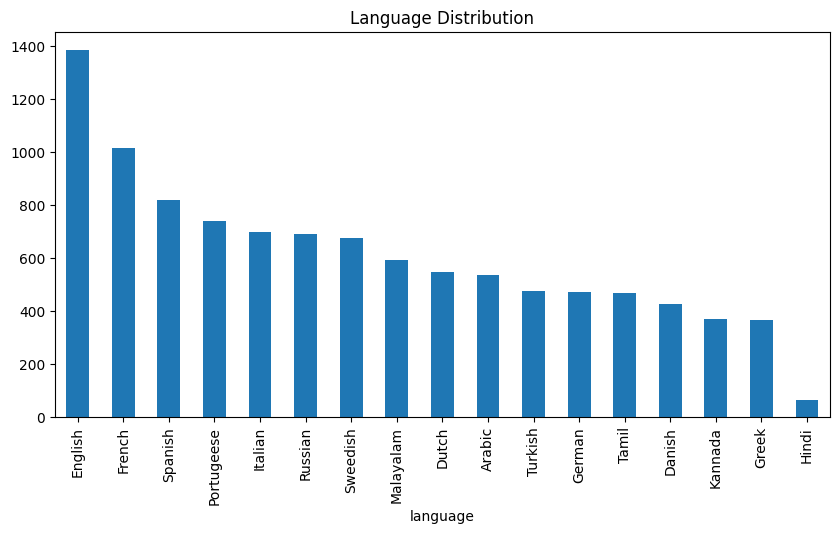

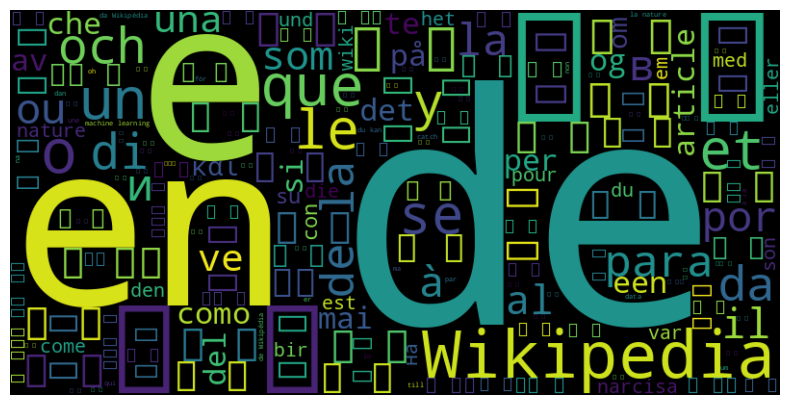


Naive Bayes Accuracy: 0.9806576402321083
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       106
           1       1.00      0.86      0.93        73
           2       0.99      0.96      0.98       111
           3       0.93      1.00      0.97       291
           4       0.98      0.99      0.98       219
           5       0.99      0.95      0.97        93
           6       1.00      0.99      0.99        68
           7       1.00      1.00      1.00        10
           8       0.99      0.98      0.99       145
           9       1.00      1.00      1.00        66
          10       1.00      0.99      1.00       121
          11       1.00      0.97      0.98       144
          12       1.00      1.00      1.00       136
          13       0.99      0.97      0.98       160
          14       0.94      0.98      0.96       133
          15       1.00      1.00      1.00        87
          16       1.00      0.98      

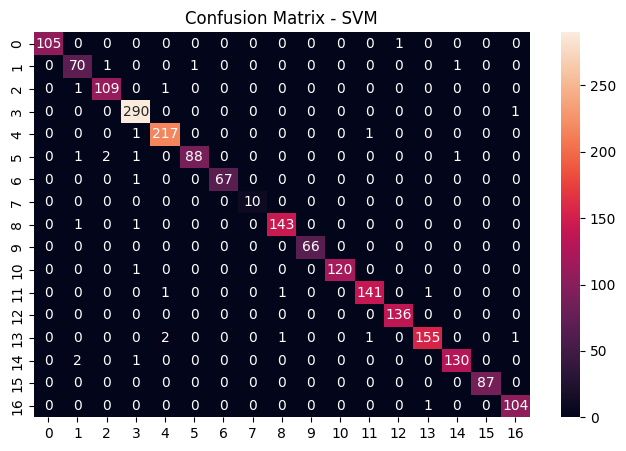

Best NB alpha: {'alpha': 0.1}
Best SVM C: {'C': 0.1}
English
French
Arabic
Russian
Spanish


['label_encoder.pkl']

In [7]:
# =========================
# 1. IMPORT LIBRARIES
# =========================
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# =========================
# 2. LOAD DATASET (FIXED PATH)
# =========================
data = pd.read_csv('/kaggle/input/datasets/tasneemgamal123/dataset/Language Detection.csv')

# normalize column names
data.columns = data.columns.str.strip().str.lower()

print(data.head())
print(data.columns)
print("Shape:", data.shape)


# =========================
# 3. EXPLORATION
# =========================
print(data['language'].value_counts())

data['text_length'] = data['text'].astype(str).apply(len)
print(data['text_length'].describe())


# =========================
# 4. VISUALIZATION
# =========================
plt.figure(figsize=(10,5))
data['language'].value_counts().plot(kind='bar')
plt.title("Language Distribution")
plt.show()

# WordCloud
text = " ".join(data['text'].astype(str))
wordcloud = WordCloud(width=800, height=400).generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()


# =========================
# 5. PREPROCESSING (FIXED)
# =========================
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)  # keep multilingual chars
    return text

data['text'] = data['text'].apply(clean_text)


# =========================
# 6. TF-IDF (IMPROVED FOR LANGUAGE DETECTION)
# =========================
vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(2,5),
    max_features=15000
)

X = vectorizer.fit_transform(data['text'])


# =========================
# 7. LABEL ENCODING
# =========================
le = LabelEncoder()
y = le.fit_transform(data['language'])


# =========================
# 8. TRAIN / TEST SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# =========================
# 9. MODELS
# =========================

# Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# SVM
svm_model = LinearSVC()
svm_model.fit(X_train, y_train)


# =========================
# 10. TESTING
# =========================

# Naive Bayes
y_pred_nb = nb_model.predict(X_test)
print("\nNaive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

# SVM
y_pred_svm = svm_model.predict(X_test)
print("\nSVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))


# Confusion Matrix (SVM)
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(8,5))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - SVM")
plt.show()


# =========================
# 11. HYPERPARAMETER TUNING
# =========================

# Naive Bayes tuning
nb_grid = {'alpha': [0.1, 0.5, 1.0]}
grid_nb = GridSearchCV(MultinomialNB(), nb_grid, cv=3)
grid_nb.fit(X_train, y_train)
print("Best NB alpha:", grid_nb.best_params_)

# SVM tuning
svm_grid = {'C': [0.1, 1, 10]}
grid_svm = GridSearchCV(LinearSVC(), svm_grid, cv=3)
grid_svm.fit(X_train, y_train)
print("Best SVM C:", grid_svm.best_params_)


# =========================
# 12. PREDICTION FUNCTION
# =========================
def predict_language(text):
    text = clean_text(text)
    vec = vectorizer.transform([text])
    pred = svm_model.predict(vec)
    return le.inverse_transform(pred)[0]


# =========================
# 13. TEST EXAMPLES
# =========================
print(predict_language("Hello how are you"))
print(predict_language("Bonjour mon ami"))
print(predict_language("مرحبا كيف حالك"))
print(predict_language("Привет как дела"))
print(predict_language("Hola como estas"))



import joblib

joblib.dump(svm_model, "language_model.pkl")
joblib.dump(vectorizer, "tfidf.pkl")
joblib.dump(le, "label_encoder.pkl")







